# Three phases and two moving interfaces

A middle layer grows into both neighbours. This **synthetic**, nondimensional
A | B | C couple uses constant matrices and two linear equilibrium families.
Its similarity solution [1] supplies a finite initial layer and a reference
for the two interface histories. It is a numerical demonstration, not material data.

Run cells from top to bottom in the `kawin` environment with the package installed.
Start the kernel in this examples directory or at the extraction repository root.
Each notebook is independent; no earlier notebook needs to have been run.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from moving_boundary.analytic import (
    FixedMatrixTernaryDiffusivity, SimilarityInitialProfile,
    solve_three_phase_similarity_roots, recorded_history,
)
from moving_boundary.equilibrium import CallableTernaryInterfaceEquilibrium
from moving_boundary.mesh import CartesianFD1D, ProfileBuilder
from moving_boundary.mesh.TransformedGrids import landau_grid
from moving_boundary.plotting import plot_composition_profiles, plot_interface_history
from moving_boundary.run_diagnostics import inventory_drift
from moving_boundary.solvers import MovingBoundaryIllingworthTernaryThreePhaseFD1DModel

## Define the two interface equilibria

Z is dependent; pairs are `[X, Y]` mole fractions. Each closure interpolates between
two specified tie lines. Its left/right endpoints follow the phase order at that
interface. Matrices, far fields, and closures are the existing `opposite` case.
Equal constant molar volumes, zero-flux outer boundaries and no bulk flow are assumed.

In [ ]:
#NOTES Might easier for the user to understand if we use a realistic example rather than a constructed one. 
elements, phases = ["Z", "X", "Y"], ["A", "B", "C"]
matrices = {
    "A": np.array([[1.0e-3, 2.0e-4], [1.0e-4, 8.0e-4]]),
    "B": np.array([[3.0e-4, -0.5e-4], [1.0e-4, 5.0e-4]]),
    "C": np.array([[6.0e-4, 1.0e-4], [-0.5e-4, 2.0e-3]]),
}
left_far, right_far = np.array([0.28, 0.10]), np.array([0.26, 0.12])
origin, domain_length = 0.3 + 1.0e-12, 0.6
start_time, final_time = 0.01, 1.0
duration = final_time - start_time

def linear_closure(left_0, left_1, right_0, right_1):
    '''Interpolate two non-crossing end tie lines in independent mole fractions.'''
    left_0, left_1, right_0, right_1 = map(np.asarray, (left_0, left_1, right_0, right_1))
    return CallableTernaryInterfaceEquilibrium(
        lambda eta: (left_0 + eta * (left_1 - left_0), right_0 + eta * (right_1 - right_0)),
        eta_bounds=(0.0, 1.0),
    )

closure_ab = linear_closure([0.30, 0.03], [0.34, 0.07], [0.18, 0.10], [0.26, 0.16])
closure_bc = linear_closure([0.20, 0.12], [0.24, 0.18], [0.36, 0.04], [0.39, 0.08])

## Start with a finite middle layer

A zero-width start is singular. Initialize from the similarity state at absolute
time 0.01, then advance for 0.99. Multiple roots can occur in coupled diffusion
problems [2]; explicitly choose the branch with the largest `k_ab`, as in the
existing example. This branch grows the middle layer into both neighbours.

In [3]:
roots = solve_three_phase_similarity_roots(
    matrices["A"], matrices["B"], matrices["C"], left_far, right_far,
    closure_ab, closure_bc, s0=origin,
)
if not roots:
    raise ValueError("No similarity root found for these inputs")
exact = max(roots, key=lambda root: root.k_ab)
mesh = CartesianFD1D(["X", "Y"], [0.0, domain_length], 6001)
mesh.setResponseProfile(ProfileBuilder([(SimilarityInitialProfile(exact, start_time), ["X", "Y"])]))
grids = (
    landau_grid(81, "linear", phase="left", spacing_ratio=0.1),
    landau_grid(81, "linear", phase="middle", spacing_ratio=0.2),
    landau_grid(81, "linear", phase="right", spacing_ratio=0.1),
)

## Build and solve

There is one transformed grid per phase and one equilibrium closure per interface.
Recording preserves all three phase profiles. A thin-phase error is a stop,
not an automatic phase-disappearance transition.

In [4]:
model = MovingBoundaryIllingworthTernaryThreePhaseFD1DModel(
    mesh=mesh, elements=elements, phases=phases,
    thermodynamics=FixedMatrixTernaryDiffusivity(matrices, phases), temperature=1000.0,
    interfacePositions=tuple(exact.interface_positions(start_time)),
    interface_equilibria=(closure_ab, closure_bc), initial_eta_guess=tuple(exact.etas),
    time_step=duration, dt_mode="semi_log", semiLog_dt=0.025, semiLogT0=1.0e-3 * start_time,
    transformed_grids=grids, tolerance=1.0e-11, max_iterations=50,
    terminal_thin_phase_policy="raise", record=True, record_pq_data=True,
)
model.solve(duration, minDtFrac=1.0e-14, verbose=True, vIt=100)

## Plot interface motion, layer thickness and profiles

Add the starting similarity time to the solver's elapsed times for the analytic
overlay. The finite domain approximates semi-infinite outer phases over this
window; the overlay does not validate real material physics.

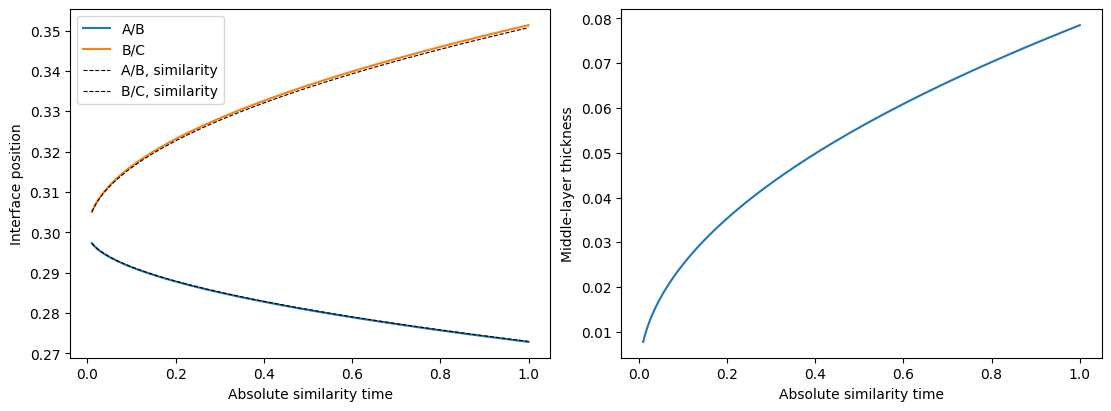

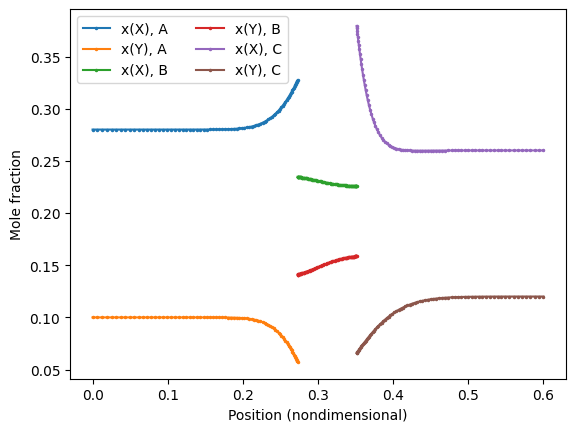

In [5]:
times, positions = recorded_history(model.interfaceData)
reference_positions = np.asarray([exact.interface_positions(t + start_time) for t in times])
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
plot_interface_history(model, ax=axes[0], time_offset=start_time)
for line, label in zip(axes[0].lines, ("A/B", "B/C")):
    line.set_label(label)
axes[0].plot(times + start_time, reference_positions, "k--", linewidth=0.8,
             label=["A/B, similarity", "B/C, similarity"])
axes[0].set(xlabel="Absolute similarity time", ylabel="Interface position")
axes[0].legend()
axes[1].plot(times + start_time, positions[:, 1] - positions[:, 0])
axes[1].set(xlabel="Absolute similarity time", ylabel="Middle-layer thickness")
plt.show()

ax = plot_composition_profiles(model, marker=".", markersize=3)
ax.set(xlabel="Position (nondimensional)", ylabel="Mole fraction")
ax.legend(ncol=2)
plt.show()

## Optional: conservation

Both interface balances must account for each component. Small total-inventory
drift is a conservation check; it alone does not establish profile accuracy.
For detailed similarity-error checks, see [the existing Python workflow](three_phase_similarity.py).

In [6]:
_, inventories = recorded_history(model.inventoryData)
absolute_drift, relative_drift = inventory_drift(inventories)
print(f"Elapsed time: {model.currentTime:g}; absolute similarity time: {start_time + model.currentTime:g}")
print(f"Final middle-layer thickness: {positions[-1, 1] - positions[-1, 0]:.6g}")
print(f"Maximum relative inventory drift: {relative_drift:.2e}")

Elapsed time: 0.99; absolute similarity time: 1
Final middle-layer thickness: 0.0784782
Maximum relative inventory drift: 1.73e-10


## Things to try

Refine each transformed grid, then compare both interface histories. Changes to
closures or far fields may introduce other roots or crossing tie lines; do not
assume that an arbitrary edited closure still defines a well-posed problem.

## References


The numbers here are synthetic; the form of the exact solution, and the possibility of more
than one root, come from the literature.

1. J. S. Kirkaldy, "Diffusion in multicomponent metallic systems: III. The motion of planar
   phase interfaces," Can. J. Phys. 36 (1958) 917-925, doi:10.1139/p58-098. Unidimensional
   diffusion in multiphase, multicomponent systems with constant diffusivities.
2. P. Maugis, W. D. Hopfe, J. E. Morral, J. S. Kirkaldy, "Multiple interface velocity
   solutions for ternary biphase infinite diffusion couples," Acta Mater. 45 (1997)
   1941-1954. More than one interface velocity can satisfy the same two-phase couple.